# Part 6 — Least squares for overdetermined systems

Exercises 6.1–6.4 from sheet section [6]: fitting a line, the quadratic cost landscape, Example 1.14 through four solvers, and the conditioning of the normal equations.

Each exercise keeps the sheet's own parts — **Task**, **Explore**, **Explain** — and every identity carries a one-line np.allclose check.

## Setup

`normal_solution` is the normal-equations solve used throughout; the rest is NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)


def normal_solution(A, b):
    """Least-squares solution from the normal equations A^T A x = A^T b."""
    return np.linalg.solve(A.T @ A, A.T @ b)


print("numpy", np.__version__)

numpy 2.5.4


## 6.1 — Fit a line, see the geometry

### Task

Generate 30 points on t ∈ [0, 1] with

    y = 2 + 0.5 t + noise,

build the 30×2 matrix A = [1, t], and fit the line by solving the normal equations

    AᵀA x̂ = Aᵀ y,    e = y − A x̂.

Plot the data, the fitted line and the vertical residuals.

t in [0.00, 1.00],  30 points
x_hat = (intercept 1.9880, slope 0.5235)   true (2.0000, 0.5000)
||e||_2 = 0.3461   max|e_i| = 0.1413   J(x_hat) = 0.1198
A^T e = (-2.22e-16, +1.25e-15)


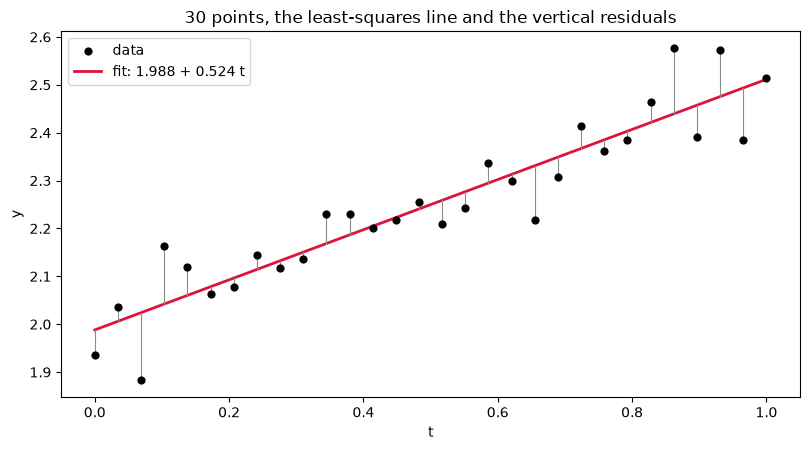

--- checks ---
A^T A x_hat = A^T y              True
A^T e = 0                        True
sum e_i = 0                      True
sum t_i e_i = 0                  True
y = A x_hat + e                  True
A has full column rank 2         True
A^T A is positive definite       True
J(x_hat + delta) >= J(x_hat)     True


In [2]:
# --- Task: 30 noisy points, the normal equations and the residuals --------
rng = np.random.default_rng(2026)
t = np.linspace(0.0, 1.0, 30)
y_line = 2.0 + 0.5 * t + 0.08 * rng.standard_normal(t.size)
A_line = np.column_stack([np.ones_like(t), t])

x_line = normal_solution(A_line, y_line)
e_line = y_line - A_line @ x_line
G_line = A_line.T @ A_line
J_line = np.sum(e_line ** 2)

print("t in [%.2f, %.2f],  %d points" % (t.min(), t.max(), t.size))
print("x_hat = (intercept %.4f, slope %.4f)   true (2.0000, 0.5000)"
      % (x_line[0], x_line[1]))
print("||e||_2 = %.4f   max|e_i| = %.4f   J(x_hat) = %.4f"
      % (np.linalg.norm(e_line), np.abs(e_line).max(), J_line))
print("A^T e = (%+.2e, %+.2e)" % tuple(A_line.T @ e_line))

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.scatter(t, y_line, s=24, color="black", zorder=3, label="data")
tt = np.linspace(t.min(), t.max(), 200)
ax.plot(tt, x_line[0] + x_line[1] * tt, color="crimson", lw=2,
        label="fit: %.3f + %.3f t" % (x_line[0], x_line[1]))
for ti, yi, fi in zip(t, y_line, A_line @ x_line):
    ax.plot([ti, ti], [yi, fi], color="0.55", lw=0.8, zorder=2)
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title("30 points, the least-squares line and the vertical residuals")
ax.legend()
fig.tight_layout()
plt.show()

D = rng.normal(scale=0.1, size=(200, 2))
J_try = np.sum((A_line @ (x_line + D).T - y_line[:, None]) ** 2, axis=0)

print("--- checks ---")
checks = {
    "A^T A x_hat = A^T y": np.allclose(G_line @ x_line, A_line.T @ y_line),
    "A^T e = 0": np.allclose(A_line.T @ e_line, 0.0),
    "sum e_i = 0": np.allclose(np.sum(e_line), 0.0),
    "sum t_i e_i = 0": np.allclose(t @ e_line, 0.0),
    "y = A x_hat + e": np.allclose(y_line, A_line @ x_line + e_line),
    "A has full column rank 2": np.linalg.matrix_rank(A_line) == 2,
    "A^T A is positive definite": np.all(np.linalg.eigvalsh(G_line) > 0),
    "J(x_hat + delta) >= J(x_hat)": np.all(J_try >= J_line - 1e-12),
}
for name, ok in checks.items():
    print("%-32s %s" % (name, ok))

### Explain

The printed Aᵀe is zero to round-off, so e is orthogonal to both columns of A and hence to the whole column space. The residual lives in the left null space N(Aᵀ), the orthogonal complement of col(A) in R³⁰; the fitted values A x̂ live in col(A).

That orthogonality is exactly the minimum condition. Write p = A x̂ and e = y − p. For any candidate x,

    y − Ax = e + A(x̂ − x).

Because e is orthogonal to every vector in col(A), the cross term in the squared norm vanishes:

    ‖y − Ax‖² = ‖e‖² + ‖A(x̂ − x)‖² ≥ ‖e‖².

The second term is nonnegative, so x̂ attains the smallest error; since A has full column rank, A(x̂ − x) = 0 forces x = x̂, so the minimiser is unique. The same condition comes from the gradient: ∇J(x) = −2Aᵀ(y − Ax), and ∇J(x̂) = 0 is exactly Aᵀe = 0, i.e. the normal equations. The Hessian 2AᵀA is positive definite, so this stationary point is the unique minimum. This is the argument of [1.8.8].

## 6.2 — The error landscape

### Task

For the line of 6.1, plot

    J(x) = ‖A x − y‖₂²

as a surface and as a contour map over the coefficient plane (x₁, x₂), and mark the least-squares solution x̂. Overlay the eigenvectors of AᵀA on the contours.

A^T A =
[[30.     15.    ]
 [15.     10.1724]]
eigenvalues = (2.1061, 38.0663)   condition number = 18.0741
J_min = J(x_hat) = 0.1198
level J_min + 1: semi-axes 0.6891 and 0.1621 along q1 and q2


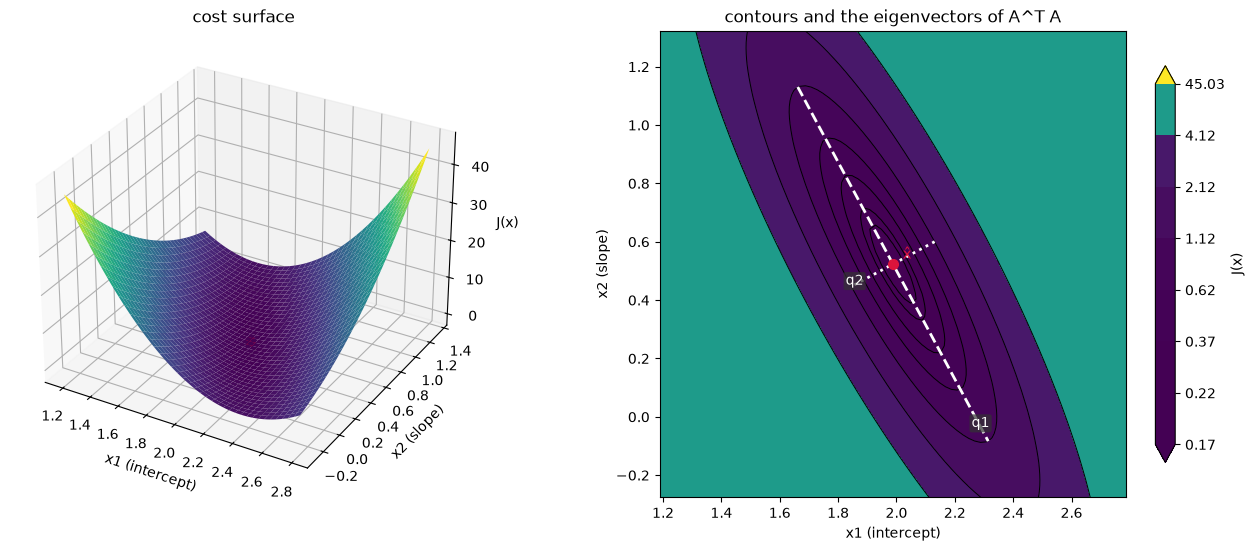

--- checks ---
A^T A is symmetric               True
eigenvalues are positive         True
eigenvalues are sigma_i(A)^2     True
gradient at x_hat is zero        True
J = J_min + d^T A^T A d          True
q_i^T A^T A q_i = lambda_i       True
semi-axis i solves d^T G d = 1   True
grid minimum at x_hat            True


In [3]:
# --- Task: J(x) as a surface and a contour map around x_hat ---------------
vals, vecs = np.linalg.eigh(G_line)
print("A^T A ="); print(G_line)
print("eigenvalues = (%.4f, %.4f)   condition number = %.4f"
      % (vals[0], vals[1], vals[-1] / vals[0]))
print("J_min = J(x_hat) = %.4f" % J_line)
print("level J_min + 1: semi-axes %.4f and %.4f along q1 and q2"
      % (1.0 / np.sqrt(vals[0]), 1.0 / np.sqrt(vals[1])))

r = 0.8
g1 = np.linspace(x_line[0] - r, x_line[0] + r, 81)
g2 = np.linspace(x_line[1] - r, x_line[1] + r, 81)
X1, X2 = np.meshgrid(g1, g2)
D1, D2 = X1 - x_line[0], X2 - x_line[1]
J = (J_line + G_line[0, 0] * D1 ** 2 + 2 * G_line[0, 1] * D1 * D2
     + G_line[1, 1] * D2 ** 2)

fig = plt.figure(figsize=(13.0, 5.4), layout="constrained")
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X1, X2, J, cmap="viridis", linewidth=0, antialiased=True)
ax.scatter([x_line[0]], [x_line[1]], [J_line], color="crimson", s=45,
           depthshade=False)
ax.set_xlabel("x1 (intercept)")
ax.set_ylabel("x2 (slope)")
ax.set_zlabel("J(x)")
ax.set_title("cost surface")

ax2 = fig.add_subplot(1, 2, 2)
levels = J_line + np.array([0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 4.0])
cf = ax2.contourf(X1, X2, J, levels=np.r_[levels, J.max()], cmap="viridis",
                  extend="both")
ax2.contour(X1, X2, J, levels=levels, colors="black", linewidths=0.7)
ax2.plot(x_line[0], x_line[1], "o", color="crimson", ms=7, zorder=5)
ax2.annotate("x\u0302", xy=(x_line[0], x_line[1]), xytext=(7, 4),
             textcoords="offset points", color="crimson", fontsize=11)
for i in range(2):
    q = vecs[:, i]
    L = 1.0 / np.sqrt(vals[i])
    ax2.plot([x_line[0] - L * q[0], x_line[0] + L * q[0]],
             [x_line[1] - L * q[1], x_line[1] + L * q[1]],
             color="white", lw=2.0, ls="--" if i == 0 else ":")
    ax2.annotate("q%d" % (i + 1),
                 xy=(x_line[0] + 0.92 * L * q[0], x_line[1] + 0.92 * L * q[1]),
                 color="white", fontsize=10, ha="center",
                 bbox=dict(boxstyle="round,pad=0.15", fc="0.2", ec="none", alpha=0.7))
ax2.set_xlabel("x1 (intercept)")
ax2.set_ylabel("x2 (slope)")
ax2.set_aspect("equal")
ax2.set_title("contours and the eigenvectors of A^T A")
fig.colorbar(cf, ax=ax2, shrink=0.85, label="J(x)")
plt.show()

dvec = np.stack([D1.ravel(), D2.ravel()], axis=1)
J_formula = J_line + np.einsum("ij,jk,ik->i", dvec, G_line, dvec).reshape(J.shape)
grad = 2 * A_line.T @ (A_line @ x_line - y_line)

print("--- checks ---")
checks = {
    "A^T A is symmetric": np.allclose(G_line, G_line.T),
    "eigenvalues are positive": np.all(vals > 0),
    "eigenvalues are sigma_i(A)^2": np.allclose(
        vals, np.sort(np.linalg.svd(A_line, compute_uv=False) ** 2)),
    "gradient at x_hat is zero": np.allclose(grad, 0.0),
    "J = J_min + d^T A^T A d": np.allclose(J, J_formula),
    "q_i^T A^T A q_i = lambda_i": np.allclose(
        [vecs[:, i] @ G_line @ vecs[:, i] for i in range(2)], vals),
    "semi-axis i solves d^T G d = 1": np.allclose(
        [(vecs[:, i] / np.sqrt(vals[i])) @ G_line
         @ (vecs[:, i] / np.sqrt(vals[i])) for i in range(2)], 1.0),
    "grid minimum at x_hat": np.allclose(
        [X1.flat[np.argmin(J)], X2.flat[np.argmin(J)]], x_line),
}
for name, ok in checks.items():
    print("%-32s %s" % (name, ok))

### Explain

The cost is quadratic:

    J(x) = (Ax − y)ᵀ(Ax − y) = xᵀAᵀAx − 2(Aᵀy)ᵀx + yᵀy.

Its gradient is 2Aᵀ(Ax − y) and its Hessian is 2AᵀA. A has full column rank here, so AᵀA is positive definite: J is strictly convex, its graph is an elliptic paraboloid (a bowl), and it has one minimum. Setting the gradient to zero gives the normal equations, so the bottom of the bowl is x̂.

Complete the square with G = AᵀA:

    J(x) = J(x̂) + (x − x̂)ᵀG(x − x̂).

Let G = QΛQᵀ with Q orthogonal and Λ = diag(λ₁, λ₂), and write d = Qᵀ(x − x̂). Then

    J = J_min + λ₁d₁² + λ₂d₂².

A level set J = J_min + c is an ellipse centred at x̂, with axes along the eigenvectors q₁, q₂ and semi-axis lengths √(c/λ₁), √(c/λ₂). A large eigenvalue means a steep direction and a short axis; a small eigenvalue means a shallow direction and a long axis. The ratio of the axes is √(λmax/λmin) = κ(A), while the condition number of G is κ(A)².

Here λ = (2.1061, 38.0663), κ(AᵀA) = 18.0741, and for c = 1 the semi-axes are 0.6891 along q₁ and 0.1621 along q₂; the contours are elongated along q₁, the direction of least curvature. This is exactly the positive definite quadratic form of Section 2 with S = AᵀA: the level sets of xᵀSx have the same axes q_i and lengths √(c/λ_i), and the surface is a bowl because both eigenvalues are positive. If A were rank-deficient, G would only be positive semidefinite, one λ would be zero, and the bowl would have a flat valley instead of a unique minimum.

## 6.3 — Reproduce Example 1.14

### Task

For

    A = [ 2  1 ]      b = [ 3 ]
        [ 1  3 ]          [ 1 ]
        [ 0  1 ]          [ 4 ]

solve A x = b with the normal equations, np.linalg.lstsq, the pseudoinverse and the QR decomposition, and compare each result with x̂ = [0.9, 0.5]. Draw the three lines of the system and the least-squares point.

solver                       x1         x2   max|.-x_ref|      ||A x-b||
normal equations       0.900000   0.500000       0.00e+00       3.834058
np.linalg.lstsq        0.900000   0.500000       1.11e-16       3.834058
pseudoinverse          0.900000   0.500000       5.55e-16       3.834058
QR                     0.900000   0.500000       4.44e-16       3.834058

x_hat = [0.9000, 0.5000]   ||e||_2 = 3.8341
A^T e = (+4.44e-16, +4.44e-16)

pairwise intersections of the three lines:
  line 1 and line 2: (+1.6000, -0.2000)   distance to x_hat = 0.9899
  line 1 and line 3: (-0.5000, +4.0000)   distance to x_hat = 3.7696
  line 2 and line 3: (-11.0000, +4.0000)   distance to x_hat = 12.4040


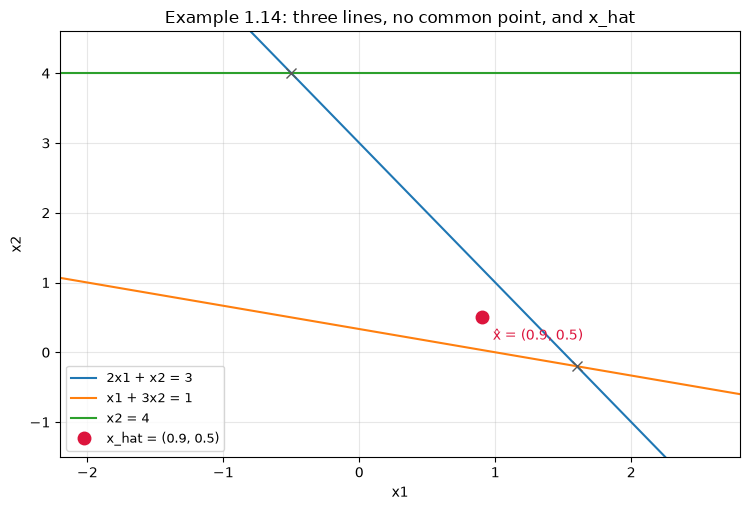

--- checks ---
all four solvers agree with x_ref      True
normal equations = inv(A^T A) A^T b    True
A^T e = 0                              True
e = b - A x_hat                        True
QR: Q^T Q = I                          True
QR: A = Q R                            True
QR: R x_hat = Q^T b                    True
rank(A) = 2                            True
system has no exact solution           True


In [4]:
# --- Task: Example 1.14 through four solvers, and the three lines --------
A_ex = np.array([[2.0, 1.0], [1.0, 3.0], [0.0, 1.0]])
b_ex = np.array([3.0, 1.0, 4.0])
x_ref = np.array([0.9, 0.5])

Q_ex, R_ex = np.linalg.qr(A_ex)
solvers = {
    "normal equations": normal_solution(A_ex, b_ex),
    "np.linalg.lstsq": np.linalg.lstsq(A_ex, b_ex, rcond=None)[0],
    "pseudoinverse": np.linalg.pinv(A_ex) @ b_ex,
    "QR": np.linalg.solve(R_ex, Q_ex.T @ b_ex),
}

print("%-20s %10s %10s %14s %14s"
      % ("solver", "x1", "x2", "max|.-x_ref|", "||A x-b||"))
for name, x in solvers.items():
    print("%-20s %10.6f %10.6f %14.2e %14.6f"
          % (name, x[0], x[1], np.abs(x - x_ref).max(),
             np.linalg.norm(A_ex @ x - b_ex)))

x_ex = solvers["normal equations"]
e_ex = b_ex - A_ex @ x_ex
print("\nx_hat = [%.4f, %.4f]   ||e||_2 = %.4f"
      % (x_ex[0], x_ex[1], np.linalg.norm(e_ex)))
print("A^T e = (%+.2e, %+.2e)" % tuple(A_ex.T @ e_ex))

print("\npairwise intersections of the three lines:")
for i, j in [(0, 1), (0, 2), (1, 2)]:
    p = np.linalg.solve(A_ex[[i, j]], b_ex[[i, j]])
    print("  line %d and line %d: (%+.4f, %+.4f)   distance to x_hat = %.4f"
          % (i + 1, j + 1, p[0], p[1], np.linalg.norm(p - x_ex)))

fig, ax = plt.subplots(figsize=(7.6, 5.2))
xx = np.linspace(-2.2, 2.8, 400)
ax.plot(xx, 3.0 - 2.0 * xx, color="C0", label="2x1 + x2 = 3")
ax.plot(xx, (1.0 - xx) / 3.0, color="C1", label="x1 + 3x2 = 1")
ax.axhline(4.0, color="C2", label="x2 = 4")
ax.plot(x_ex[0], x_ex[1], "o", color="crimson", ms=9, zorder=5,
        label="x_hat = (0.9, 0.5)")
ax.annotate("x\u0302 = (%.1f, %.1f)" % (x_ex[0], x_ex[1]), xy=x_ex,
            xytext=(8, -16), textcoords="offset points", color="crimson")
for i, j in [(0, 1), (0, 2)]:
    p = np.linalg.solve(A_ex[[i, j]], b_ex[[i, j]])
    ax.plot(p[0], p[1], "x", color="0.35", ms=7)
ax.set_xlim(-2.2, 2.8)
ax.set_ylim(-1.5, 4.6)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="best")
ax.set_title("Example 1.14: three lines, no common point, and x_hat")
fig.tight_layout()
plt.show()

print("--- checks ---")
checks = {
    "all four solvers agree with x_ref": all(
        np.allclose(x, x_ref) for x in solvers.values()),
    "normal equations = inv(A^T A) A^T b": np.allclose(
        x_ex, np.linalg.inv(A_ex.T @ A_ex) @ A_ex.T @ b_ex),
    "A^T e = 0": np.allclose(A_ex.T @ e_ex, 0.0),
    "e = b - A x_hat": np.allclose(e_ex, b_ex - A_ex @ x_ex),
    "QR: Q^T Q = I": np.allclose(Q_ex.T @ Q_ex, np.eye(2)),
    "QR: A = Q R": np.allclose(A_ex, Q_ex @ R_ex),
    "QR: R x_hat = Q^T b": np.allclose(R_ex @ x_ex, Q_ex.T @ b_ex),
    "rank(A) = 2": np.linalg.matrix_rank(A_ex) == 2,
    "system has no exact solution": not np.allclose(A_ex @ x_ex, b_ex),
}
for name, ok in checks.items():
    print("%-38s %s" % (name, ok))

### Explain

All four solvers return x̂ = [0.900000, 0.500000]; the largest entrywise difference from [0.9, 0.5] is at most 5.6×10⁻¹⁶, and all four residuals are 3.834058.

The normal equations solve AᵀA x = Aᵀb. Since A has rank 2, AᵀA is invertible and x̂ = (AᵀA)⁻¹Aᵀb. `np.linalg.lstsq` minimises ‖Ax − b‖ directly using an SVD, and `np.linalg.pinv(A) @ b` uses the same SVD pseudoinverse; for full column rank both equal the normal-equations solution. QR writes A = QR with QᵀQ = I and R upper triangular. Then AᵀA = RᵀR and Aᵀb = RᵀQᵀb, so the normal equations reduce to Rx = Qᵀb, which is what the QR solver uses. The four roads compute the same unique minimiser.

The system has no exact solution: b is not in col(A). The printed pairwise intersections (1.6, −0.2), (−0.5, 4), (−11, 4) are all different, so the three lines do not meet in one point; x̂ is not one of these intersections. The residual is e = b − Ax̂ = [0.7, −1.4, 3.5], with ‖e‖ = 3.8341 and Aᵀe = 0. Thus Ax̂ is the orthogonal projection of b onto col(A), and x̂ is the point whose image is closest to b. Figure 4 (right) shows exactly this: the three lines and the compromise point.

QR is also the more stable of the four: it works with R and Q without forming AᵀA, so it avoids squaring the condition number; the normal-equations route is the one that suffers in 6.4.

## 6.4 — When the normal equations go wrong

### Task

Fit a degree-10 polynomial with

    A = [1, t, t², ..., t¹⁰]

to 30 points on t ∈ [0, 1]. The data are the exact polynomial

    y = T₁₀(2t − 1),

where T₁₀ is the Chebyshev polynomial of degree 10, so the coefficient vector is known. Compare the normal-equations solution with np.linalg.lstsq: print both coefficient vectors, the relative coefficient errors and the residuals.

In [ ]:
# --- Task: degree-10 monomial fit, normal equations vs lstsq ---------------
t_poly = np.linspace(0.0, 1.0, 30)
c_true = np.array([1.0, -200.0, 6600.0, -84480.0, 549120.0,
                   -2050048.0, 4659200.0, -6553600.0, 5570560.0,
                   -2621440.0, 524288.0])
A_poly = np.vander(t_poly, 11, increasing=True)
y_poly = A_poly @ c_true

x_normal = normal_solution(A_poly, y_poly)
x_lstsq = np.linalg.lstsq(A_poly, y_poly, rcond=None)[0]
G_poly = A_poly.T @ A_poly
e_normal = y_poly - A_poly @ x_normal
e_lstsq = y_poly - A_poly @ x_lstsq

print("%3s %14s %14s %14s" % ("k", "true", "normal", "lstsq"))
for k in range(11):
    print("%3d %14.4f %14.4f %14.4f"
          % (k, c_true[k], x_normal[k], x_lstsq[k]))
print("\nrelative coefficient error: normal %.3e   lstsq %.3e"
      % (np.linalg.norm(x_normal - c_true) / np.linalg.norm(c_true),
         np.linalg.norm(x_lstsq - c_true) / np.linalg.norm(c_true)))
print("residual ||A x - y||: normal %.3e   lstsq %.3e"
      % (np.linalg.norm(e_normal), np.linalg.norm(e_lstsq)))
print("normal-equation residual ||A^T e||: normal %.3e   lstsq %.3e"
      % (np.linalg.norm(A_poly.T @ e_normal),
         np.linalg.norm(A_poly.T @ e_lstsq)))

print("--- checks ---")
checks = {
    "data are T10(2t - 1)": np.allclose(
        y_poly, np.cos(10 * np.arccos(2 * t_poly - 1)), atol=1e-10),
    "lstsq recovers the true coefficients": np.allclose(
        x_lstsq, c_true, atol=1e-6),
    "normal equations miss the true coefficients": not np.allclose(
        x_normal, c_true, atol=1e-6),
    "normal equations solve A^T A x = A^T y": np.allclose(
        G_poly @ x_normal, A_poly.T @ y_poly),
    "lstsq solves A^T A x = A^T y": np.allclose(
        G_poly @ x_lstsq, A_poly.T @ y_poly),
}
for name, ok in checks.items():
    print("%-46s %s" % (name, ok))

  k           true         normal          lstsq
  0         1.0000         0.9999         1.0000
  1      -200.0000      -199.9245      -200.0000
  2      6600.0000      6597.3629      6600.0000
  3    -84480.0000    -84445.8812    -84480.0000
  4    549120.0000    548897.4378    549120.0001
  5  -2050048.0000  -2049214.8531  -2050048.0003
  6   4659200.0000   4657300.5821   4659200.0007
  7  -6553600.0000  -6550918.4405  -6553600.0010
  8   5570560.0000   5568271.2111   5570560.0008
  9  -2621440.0000  -2620358.1143  -2621440.0004
 10    524288.0000    524070.6196    524288.0001

relative coefficient error: normal 4.095e-04   lstsq 1.539e-10
residual ||A x - y||: normal 1.594e-03   lstsq 5.917e-09
normal-equation residual ||A^T e||: normal 8.046e-09   lstsq 2.591e-08
--- checks ---
data are T10(2t - 1)                           True
lstsq recovers the true coefficients           True
normal equations miss the true coefficients    True
normal equations solve A^T A x = A^T y         Tr

### Explore

Print cond(A) and cond(AᵀA), and their ratio.

In [6]:
# --- Explore: the two condition numbers ------------------------------------
cond_A = np.linalg.cond(A_poly)
cond_G = np.linalg.cond(G_poly)
s_poly = np.linalg.svd(A_poly, compute_uv=False)

print("cond(A)      = %.6e" % cond_A)
print("cond(A^T A)  = %.6e" % cond_G)
print("cond(A)^2    = %.6e" % (cond_A ** 2))
print("ratio cond(A^T A) / cond(A)^2 = %.6f" % (cond_G / cond_A ** 2))
print("sigma_max = %.6e   sigma_min = %.6e" % (s_poly[0], s_poly[-1]))

print("--- checks ---")
checks = {
    "A columns are 1, t, ..., t^10": all(
        np.allclose(A_poly[:, k], t_poly ** k) for k in range(11)),
    "cond(A^T A) = cond(A)^2": np.allclose(cond_G, cond_A ** 2, rtol=1e-2),
    "eigenvalues of A^T A are sigma_i^2": np.allclose(
        np.sort(np.linalg.eigvalsh(G_poly)), np.sort(s_poly ** 2)),
}
for name, ok in checks.items():
    print("%-38s %s" % (name, ok))

cond(A)      = 2.067173e+07
cond(A^T A)  = 4.267653e+14
cond(A)^2    = 4.273202e+14
ratio cond(A^T A) / cond(A)^2 = 0.998701
sigma_max = 7.473545e+00   sigma_min = 3.615347e-07
--- checks ---
A columns are 1, t, ..., t^10          True
cond(A^T A) = cond(A)^2                True
eigenvalues of A^T A are sigma_i^2     True


### Explain

Write the SVD of A as A = UΣVᵀ. Then

    AᵀA = VΣᵀΣVᵀ = V diag(σ₁², ..., σ₁₁²) Vᵀ,

so the eigenvalues of AᵀA are exactly the squared singular values of A, and

    κ(AᵀA) = σmax² / σmin² = κ(A)².

This is the identity in the sheet. The printed values confirm it: κ(A) = 2.0672×10⁷, κ(AᵀA) = 4.2677×10¹⁴, and their ratio is 0.9987 (the small difference is round-off in the two condition-number estimates).

The normal equations square the condition number, and that is what makes them less accurate. Forming AᵀA squares every singular value; the smallest one, σmin = 3.615×10⁻⁷, becomes about 1.3×10⁻¹³, only about 2×10⁻¹⁵ of the largest eigenvalue, i.e. a few round-off units. A relative perturbation ε in the data or in forming AᵀA can be amplified by κ(AᵀA) = κ(A)² in the solution, whereas a method that works directly with A is amplified only by κ(A). Here κ(A)²ε is of order 0.1 in double precision, so several digits of the coefficient vector are lost.

The run shows the effect. The data are exactly the degree-10 polynomial T₁₀(2t − 1), so the true coefficient vector is known. lstsq recovers it with relative error 1.5×10⁻¹⁰ and residual 5.9×10⁻⁹. The normal-equations solution has relative coefficient error 4.1×10⁻⁴ and residual 1.6×10⁻³: it is a different coefficient vector, although its fitted values agree with y to plotting accuracy, and it satisfies AᵀAx = Aᵀy to round-off. That last observation is the important one: a small normal-equation residual does not guarantee an accurate x when AᵀA is ill-conditioned, because a whole family of coefficient vectors produces almost the same fitted values. The monomial columns 1, t, ..., t¹⁰ are highly correlated on [0, 1], which is the source of the large condition number.